# 2. Is the scoring rate constant through a match?

Let's look at *when* goals are scored.

For a Poisson process with a constant rate, if you are told there were N events in the interval [0, T], the times of those events are distributed like N independent draws from Uniform(0, T).

This notebook then tests for constancy in time, separately from the between-match differences.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from load import load

matches, goals = load("../data/worldcup.json")

reg = goals[~goals.in_extra_time]          
clean = reg[reg.stoppage == 0]             
stop = reg[reg.stoppage > 0]

print(f"regulation goals: {len(reg)}")
print(f"  in the 90 nominal minutes: {len(clean)}")
print(f"  in stoppage time:          {len(stop)}"
      f"  (first half {(stop.minute == 45).sum()}, second half {(stop.minute == 90).sum()})")

regulation goals: 796
  in the 90 nominal minutes: 697
  in stoppage time:          99  (first half 23, second half 76)


## 2.1 A Caveat on Stoppage Time

A goal recorded at "90+4" was scored in the 94th minute of play, but the data does not say how long stoppage time lasted in each match. So we know how many goals were scored in stoppage time, but not how much time they were scored in.

As such, the tests below use only goals from the 90 nominal minutes, where every minute is exactly one minute of play in every match. Stoppage-time goals are shown in the plot but kept out of the tests. This is conservative: if there are extra goals late in each half, leaving stoppage time out can only hide them.

## 2.2 Goals by 15-minute period

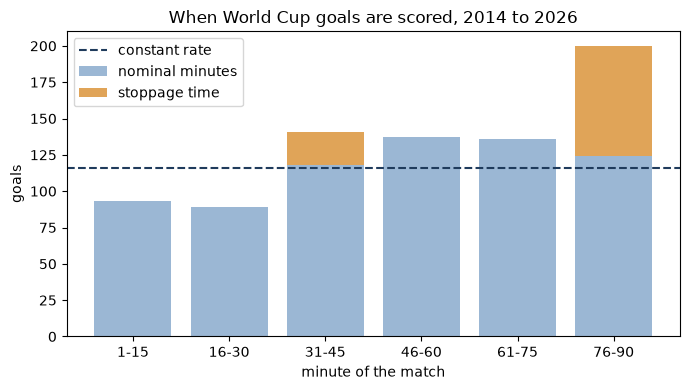

period  goals  stoppage
  1-15     93         0
 16-30     89         0
 31-45    118        23
 46-60    137         0
 61-75    136         0
 76-90    124        76


In [2]:
edges = np.arange(0, 91, 15)
labels = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]

# a goal in minute m was scored in the interval (m-1, m]
counts, _ = np.histogram(clean.minute - 0.5, bins=edges)
stop_counts = np.array([0, 0, (stop.minute == 45).sum(), 0, 0, (stop.minute == 90).sum()])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, counts, color="#9bb7d4", label="nominal minutes")
ax.bar(labels, stop_counts, bottom=counts, color="#e0a458", label="stoppage time")
ax.axhline(counts.mean(), color="#1f3b5c", linestyle="--", label="constant rate")
ax.set_xlabel("minute of the match")
ax.set_ylabel("goals")
ax.set_title("When World Cup goals are scored, 2014 to 2026")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/02_goals_by_period.png", dpi=150)
plt.show()

print(pd.DataFrame({"period": labels, "goals": counts, "stoppage": stop_counts}).to_string(index=False))

## 2.3 Chi-square test across the six periods

**Null hypothesis:** the rate is constant, so each 15-minute period gets one sixth of the goals.

In [3]:
chi2, p_chi2 = st.chisquare(counts)
print(f"expected per period: {counts.mean():.1f}")
print(f"chi-square = {chi2:.2f}, df = 5, p = {p_chi2:.4f}")

expected per period: 116.2
chi-square = 18.65, df = 5, p = 0.0022


## 2.4 Kolmogorov-Smirnov test on the goal times

The chi-square test depends on where the bin edges are. Now, we want to use the Kolmogorov-Smirnov test to use the times themselves, so that we can compare the empirical distribution function of the goal times with the Uniform(0, 90) one and report the largest gap.

KS statistic = 0.079, p = 0.00033
largest gap is at minute 47


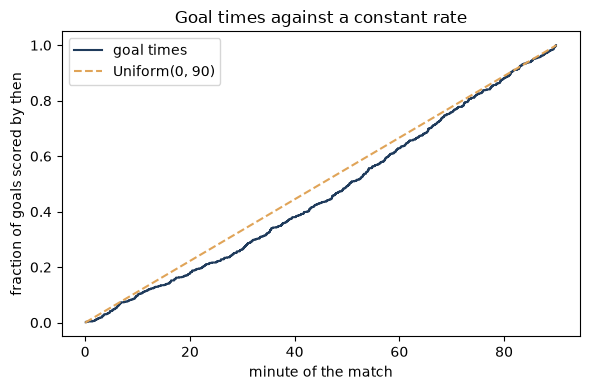

In [6]:
rng = np.random.default_rng(0)
t = clean.minute.to_numpy() - rng.uniform(0, 1, len(clean))

ks = st.kstest(t, st.uniform(0, 90).cdf)
print(f"KS statistic = {ks.statistic:.3f}, p = {ks.pvalue:.5f}")
print(f"largest gap is at minute {ks.statistic_location:.0f}")

ts = np.sort(t)
fig, ax = plt.subplots(figsize=(6, 4))
ax.step(ts, np.arange(1, len(ts) + 1) / len(ts), color="#1f3b5c", label="goal times")
ax.plot([0, 90], [0, 1], "--", color="#e0a458", label="Uniform(0, 90)")
ax.set_xlabel("minute of the match")
ax.set_ylabel("fraction of goals scored by then")
ax.set_title("Goal times against a constant rate")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/02_goal_times_ecdf.png", dpi=150)
plt.show()

## 2.5 First half against second half

The simplest version of the question. Under a constant rate, each goal is equally likely to fall in either half, so the first-half count is Binomial(N, 1/2).

In [8]:
first = (clean.minute <= 45).sum()
second = len(clean) - first
p_half = st.binomtest(first, len(clean), 0.5).pvalue
print(f"first half: {first}   second half: {second}   ratio: {second / first:.2f}")
print(f"binomial test p = {p_half:.5f}")

first half: 300   second half: 397   ratio: 1.32
binomial test p = 0.00027


## Conclusion

The scoring rate is not constant through a match. Using only the 697 goals scored in the 90 nominal minutes, all three tests reject a constant rate: the chi-square test across six 15-minute periods (chi-square = 18.65, df = 5, p = 0.002), the Kolmogorov-Smirnov test on the goal times (p = 0.0003), and the first-half against second-half comparison (300 against 397 goals, p = 0.0003).

The first half hour is quiet, with 93 and 89 goals in the first two periods against 116 expected, and from minute 31 onward every period is above the average. The second half has about 1.3 times as many goals as the first.

These tests leave stoppage time out, because the data does not record how long it lasted. That makes the result conservative: 76 goals came in second-half stoppage time and 23 in first-half stoppage time, so the true late-match rate is higher than the nominal minutes show.

The next notebook fits a rate that changes with time and checks whether that model is adequate.